# 04 — Diagnóstico com machine learning

**Pergunta.** A taxa manual está deixando de capturar alguma estrutura de mortalidade (uma interação, um efeito
não linear, uma variável que não está na tarifa)?

**Método.** Um gradient boosting (LightGBM) com perda Poisson que parte da taxa manual:

$$
\log \mu_c = \log \mu^{\text{manual}}_c + F(x_c),
$$

em que $\mu^{\text{manual}}_c$ são os óbitos esperados pela tabela de fatores da Etapa 2 (entra como offset,
`init_score`) e $F$ é a soma de árvores rasas. O modelo só aprende o que a manual **não** explica; se $F \approx 0$,
não falta estrutura. A interpretação usa a decomposição SHAP que o próprio LightGBM calcula (TreeSHAP):

$$
F(x_c) = \phi_0 + \sum_j \phi_j(x_c),
$$

em que $\phi_j$ é a contribuição da variável $j$, em log, para o desvio em relação à manual.

**Regras do diagnóstico:**
- validação deixando **grupos inteiros** de fora, com parada antecipada; a melhora só conta se a diferença de
  deviance fora da amostra tiver intervalo de 95% (bootstrap pareado por grupo) inteiramente abaixo de zero;
- o estipulante fica de fora das variáveis: procuramos fatores de tarifa, não o efeito de cada grupo;
- **o ML não entra na tarifa.** O que ele apontar vira hipótese testada no GLMM (glmmTMB), com razão de
  verossimilhança. Hipóteses de subscrição concretas também são testadas ali, diretamente.

In [1]:
import sys, warnings
warnings.filterwarnings("ignore", message="Efeitos aleatórios com variância nula")   # informado explicitamente no notebook 03b
from pathlib import Path
RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ / "src"))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from vgpricing.config import carregar_config
from vgpricing.tabua import obter_tabua
from vgpricing import manual as M, diagnostico as D

pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
cfg, cm, cd = (carregar_config(n, RAIZ) for n in ("base", "manual", "diagnostico"))
with warnings.catch_warnings():
    warnings.filterwarnings("ignore", message=".*coluna lx.*")
    tabua = obter_tabua(cfg, RAIZ)
dados = {t: pd.read_parquet(RAIZ / cfg["pasta_processados"] / "limpo" / f"{t}.parquet") for t in ("estipulantes", "vidas", "sinistros")}
tabela = M.carregar_tabela(RAIZ / "artefatos/fatores_manual.yaml")       # gerada no notebook 03b
df = D.base_diagnostico(dados["vidas"], dados["sinistros"], dados["estipulantes"], tabua, tabela,
                        cfg["data_referencia"], cm["meses_maturacao"])
pd.Series({"linhas": len(df), "óbitos": df["N"].sum(), "esperados pela manual": df["mu_manual"].sum(),
           "A/E contra a manual": df["N"].sum() / df["mu_manual"].sum()}).to_frame("base")

,base
linhas,"137,473.0000"
óbitos,"1,686.0000"
esperados pela manual,"1,686.1794"
A/E contra a manual,0.9999


## 1. O LightGBM melhora a previsão em grupos que não viu?

In [2]:
r = D.ajustar_residual(df, cd)
c = r["comparacao"]
pd.Series({"rodadas (parada antecipada)": r["rodadas"], "deviance fora da amostra: manual": c["deviance_manual"],
           "deviance fora da amostra: manual + LightGBM": c["deviance_gbm"], "diferença": c["diferenca"],
           "IC95 inferior": c["ic95"][0], "IC95 superior": c["ic95"][1],
           "melhora significativa": c["melhora_significativa"]}).to_frame("resultado")

,resultado
rodadas (parada antecipada),23
deviance fora da amostra: manual,352.4485
deviance fora da amostra: manual + LightGBM,349.9902
diferença,-2.4583
IC95 inferior,-8.5797
IC95 superior,3.9145
melhora significativa,False


## 2. Lift duplo

As linhas são ordenadas pela razão $\mu^{\text{LightGBM}} / \mu^{\text{manual}}$ (fora da amostra) e divididas em dez
faixas de igual esperado. Se o LightGBM captura estrutura real, o observado acompanha o previsto; se captura ruído,
o observado fica plano em torno de 1.

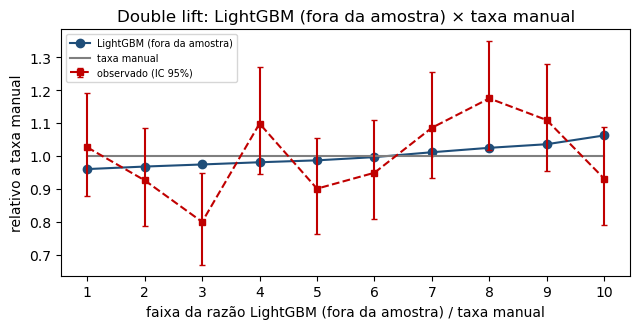

,mu_gbm,mu_manual,observado,obs_inf,obs_sup
faixa,,,,,
1,0.9602,1.0000,1.0261,0.8789,1.1909
2,0.9678,1.0000,0.9261,0.7865,1.0833
3,0.9742,1.0000,0.8000,0.6708,0.9469
4,0.9809,1.0000,1.0982,0.9456,1.2683
5,0.9867,1.0000,0.9008,0.7633,1.0559
6,0.9965,1.0000,0.9490,0.8077,1.1080
7,1.0112,1.0000,1.0854,0.9339,1.2546
8,1.0247,1.0000,1.1745,1.0166,1.3500
9,1.0356,1.0000,1.1089,0.9556,1.2797


In [3]:
from vgpricing import avaliacao as A
d = df.assign(mu_gbm=r["mu_gbm_oof"])
lift = A.double_lift(d, "mu_gbm", "mu_manual", base="mu_manual")
fig, ax = plt.subplots(figsize=(6.5, 3.4))
A.grafico_double_lift(ax, lift, "LightGBM (fora da amostra)", "taxa manual")
plt.tight_layout(); plt.show()
lift

## 3. Onde o LightGBM mexe (SHAP)

In [4]:
contrib = D.contribuicoes(r["modelo"], r["X"])
imp = D.importancia(contrib, df["mu_manual"].to_numpy())
imp.to_frame("média |SHAP| (log), ponderada pelos esperados")

,"média |SHAP| (log), ponderada pelos esperados"
cnae_divisao,0.0216
log_porte,0.0064
cnae_secao,0.0026
idade,0.0015
contributario,0.0012
sexo,0.0000
log_capital,0.0000
tipo_capital,0.0000
ano_calendario,0.0000


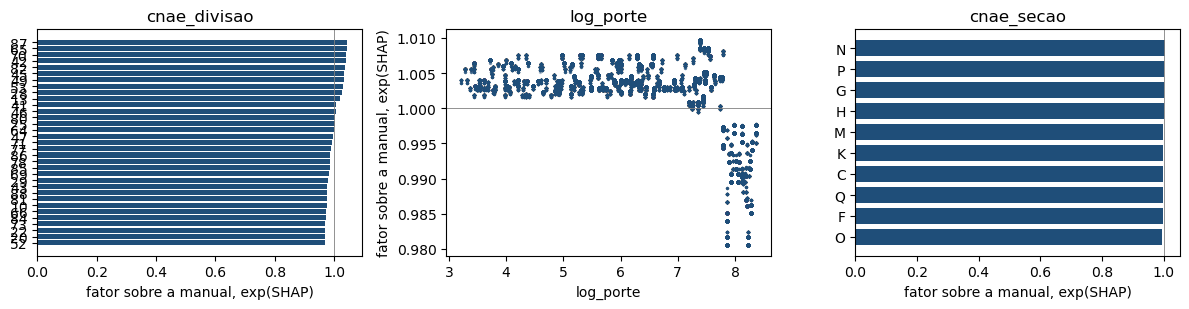

In [5]:
top = [v for v in imp.index[:3]]
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
for a, v in zip(ax, top):
    x = df[v]
    if x.dtype == object or str(x.dtype) in ("string", "category"):
        m = contrib.groupby(x.astype(str))[v].mean().sort_values()
        a.barh(m.index, np.exp(m.values), color="#1f4e79"); a.axvline(1, color="grey", lw=0.6)
        a.set_xlabel("fator sobre a manual, exp(SHAP)")
    else:
        a.scatter(x, np.exp(contrib[v]), s=2, alpha=0.3, color="#1f4e79"); a.axhline(1, color="grey", lw=0.6)
        a.set_ylabel("fator sobre a manual, exp(SHAP)"); a.set_xlabel(v)
    a.set_title(v)
plt.tight_layout(); plt.show()

In [6]:
if c["melhora_significativa"]:
    print("O LightGBM melhora a previsão fora da amostra. Variáveis a investigar, em ordem:", list(imp.index[:3]))
    print("Próximo passo: traduzir o padrão do gráfico acima num termo parcimonioso e testá-lo no GLMM (seção 4).")
else:
    print("Sem melhora significativa fora da amostra: não há estrutura faltante detectável com este volume.")
    print("As contribuições SHAP acima são pequenas e não devem ser lidas como efeitos.")

Sem melhora significativa fora da amostra: não há estrutura faltante detectável com este volume.
As contribuições SHAP acima são pequenas e não devem ser lidas como efeitos.


As contribuições são pequenas (frações de 1% na escala do fator) e a parada antecipada ocorre cedo: o modelo
quase não sai da taxa manual. Na carteira sintética isso é esperado, mas um resultado nulo só vale se o método
tiver **poder** para detectar estrutura quando ela existe. O notebook `90_validacao_sintetica` mede isso plantando
efeitos conhecidos: com este volume, o diagnóstico só encontra estrutura que afeta centenas de óbitos esperados.

## 4. Hipóteses dirigidas: teste direto no GLMM

Hipóteses de subscrição concretas não precisam esperar o ML: testam-se direto no GLMM da taxa manual, com muito
mais poder. Exemplo: **o efeito do capital é diferente quando o capital é múltiplo do salário?** Nesse tipo de
apólice, capital alto indica salário alto; no capital uniforme, não indica nada. O termo testado é a interação
$\beta_{\text{cap}\times\text{tipo}}\,\log(C/C_{\text{ref}}) \times \mathbb{1}[\text{tipo}]$, com o efeito principal
do tipo de capital no modelo.

In [7]:
D.testar_candidato_glmm(df, cm, ["log_capital_c", "cnae_secao", "tipo_capital"], ["log_capital_c:tipo_capital"],
                        categoricas_extras=["tipo_capital"])

,termo,tipo,lr,gl,p_valor,coeficientes
0,log_capital_c:tipo_capital,fixo,0,0,1,"{'log_capital_c': nan, 'log_capital_c:tipo_cap..."


Se o p-valor for baixo, o termo é candidato a entrar na tarifa: volta para a Etapa 2 como fator candidato
(com a correção de Holm junto dos demais) e para a decisão de negócio. Se for alto, a tarifa fica como está e o
teste fica documentado.

## Limitações
- **Poder:** com milhares de óbitos, o ML exploratório só encontra estrutura grande. Em bases maiores (a base real
  de uma seguradora, vários anos) o mesmo notebook roda sem mudança e o poder aumenta.
- **Offset fixo:** a taxa manual entra como dada; a incerteza dela não é considerada no diagnóstico.
- **Parada antecipada escolhida na validação cruzada:** a deviance fora da amostra é levemente otimista para o
  LightGBM, o que joga a favor de encontrar estrutura; mesmo assim, aqui nada aparece.